# T07 · EDA: correlação e checagem de vazamento

**Issue:** #7 · **Fase 1 · EDA** · **Dataset:** `data/raw/cardio_train.csv`

**Objetivo:** entender como as variáveis se relacionam entre si e com o alvo (`cardio`), e garantir que nenhuma coluna
entregue a resposta ao modelo. A análise alimenta a engenharia de atributos (**T10**) e os testes de vazamento (**T12**).

> A análise usa os dados **limpos** (`load_dataset()` + `clean()`): com os valores impossíveis de pressão, os outliers
> distorcem a correlação (seção 1). As variáveis derivadas do conjunto B (`imc`, `pressao_pulso` e `pam`) entram pelo
> `add_features()`, o mesmo código que os modelos usam.
> Todos os números dos textos são **calculados a partir do dataset**.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

# Permite rodar o notebook fora do Docker (no Docker o PYTHONPATH já aponta para src/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import roc_auc_score

from cardio.config import DATA_PATH, FIGURES_DIR, TARGET
from cardio.data.loader import load_dataset
from cardio.data.preprocessing import clean
from cardio.features.build import FEATURES_A, add_features

sns.set_theme(style="whitegrid")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

NOMES = {
    "age_years": "Idade", "sex_male": "Sexo masculino", "height": "Altura", "weight": "Peso",
    "imc": "IMC", "ap_hi": "Sistólica", "ap_lo": "Diastólica", "pressao_pulso": "Pressão de pulso",
    "pam": "PAM", "cholesterol": "Colesterol", "gluc": "Glicose", "smoke": "Fuma",
    "alco": "Bebe álcool", "active": "Atividade física", "cardio": "Doença (alvo)", "id": "id",
}
DERIVADAS_NUMERICAS = ["imc", "pressao_pulso", "pam"]  # categoria_pressao e faixa_imc são texto
FEATURES_B_NUMERICAS = FEATURES_A + DERIVADAS_NUMERICAS


def salvar(fig, nome: str) -> None:
    """Salva a figura em results/figures/ com o prefixo da tarefa."""
    fig.savefig(FIGURES_DIR / f"t07_{nome}.png", dpi=120, bbox_inches="tight")


def pct(valor: float, casas: int = 0) -> str:
    """Formata uma proporção (0–1) como porcentagem no padrão brasileiro: 0.497 -> '49,7%'."""
    return f"{valor * 100:.{casas}f}%".replace(".", ",")


def num(valor: float, casas: int = 2) -> str:
    """Formata um número com vírgula decimal: 0.238 -> '0,24'."""
    return f"{valor:.{casas}f}".replace(".", ",")


def inteiro(valor: int) -> str:
    """Formata um inteiro com ponto de milhar: 68588 -> '68.588'."""
    return f"{valor:,}".replace(",", ".")


def texto(conteudo: str) -> None:
    """Mostra um texto de interpretação formatado em Markdown."""
    display(Markdown(conteudo))

In [2]:
bruto = load_dataset(DATA_PATH)
df = add_features(clean(bruto, verbose=False))
df.attrs = {}  # o log da limpeza (um DataFrame) não deve acompanhar as tabelas derivadas

print(f"{inteiro(len(bruto))} pacientes no dataset bruto | {inteiro(len(df))} após a limpeza | "
      f"{pct(df[TARGET].mean(), 1)} com doença cardiovascular")

70.000 pacientes no dataset bruto | 68.509 após a limpeza | 49,5% com doença cardiovascular


## 1. Heatmap de correlação

Correlação de Pearson entre todas as variáveis numéricas (originais e derivadas) e o alvo. Para as binárias (`sex_male`,
`smoke`, `alco`, `active`) e as ordinais (`cholesterol`, `gluc`), a correlação de Pearson com o alvo equivale à
correlação ponto-bisserial: mede se a taxa de doença sobe ou desce com a variável. O `id` fica de fora aqui e é
analisado na seção 4.

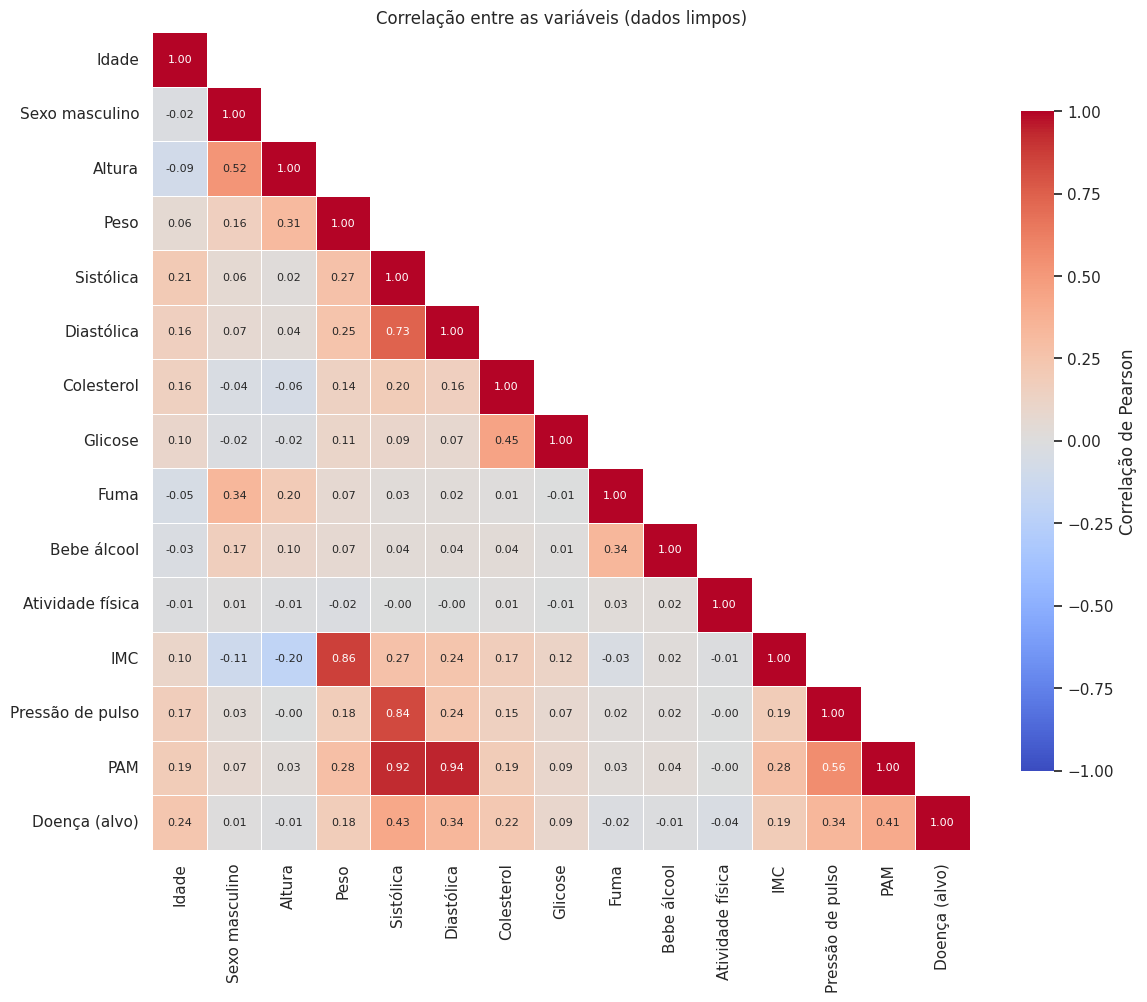

In [3]:
colunas = FEATURES_B_NUMERICAS + [TARGET]
correlacao = df[colunas].corr()

fig, ax = plt.subplots(figsize=(12, 10))
mascara = np.triu(np.ones_like(correlacao, dtype=bool), k=1)
sns.heatmap(correlacao.rename(index=NOMES, columns=NOMES), mask=mascara, annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True, linewidths=0.5,
            annot_kws={"size": 8}, cbar_kws={"label": "Correlação de Pearson", "shrink": 0.8}, ax=ax)
ax.set_title("Correlação entre as variáveis (dados limpos)")
ax.grid(False)
plt.tight_layout()
salvar(fig, "heatmap_correlacao")
plt.show()

In [4]:
r_bruto = bruto[["ap_hi", "ap_lo"]].corrwith(bruto[TARGET])
r_limpo = df[["ap_hi", "ap_lo"]].corrwith(df[TARGET])

texto(f"""**Por que filtrar antes:** nos dados **brutos**, a correlação da sistólica com o alvo é de só
{num(r_bruto["ap_hi"], 3)} e a da diastólica, {num(r_bruto["ap_lo"], 3)}. Depois da limpeza (T08), elas passam a
**{num(r_limpo["ap_hi"], 3)}** e **{num(r_limpo["ap_lo"], 3)}**. Os poucos valores absurdos (ex.: 16.020 mmHg ou pressões
negativas) dominam a média e o desvio-padrão e escondem a variável mais importante do dataset. Por isso toda a análise
usa os dados limpos, o mesmo conjunto que os modelos veem.""")

**Por que filtrar antes:** nos dados **brutos**, a correlação da sistólica com o alvo é de só
0,054 e a da diastólica, 0,066. Depois da limpeza (T08), elas passam a
**0,428** e **0,340**. Os poucos valores absurdos (ex.: 16.020 mmHg ou pressões
negativas) dominam a média e o desvio-padrão e escondem a variável mais importante do dataset. Por isso toda a análise
usa os dados limpos, o mesmo conjunto que os modelos veem.

## 2. Ranking da correlação com o alvo

Pearson mede relação **linear**; Spearman usa a ordem dos valores e capta qualquer relação que só sobe (ou só desce).
Quando as duas são parecidas, a relação é aproximadamente monotônica. A tabela compara com os valores esperados na issue.

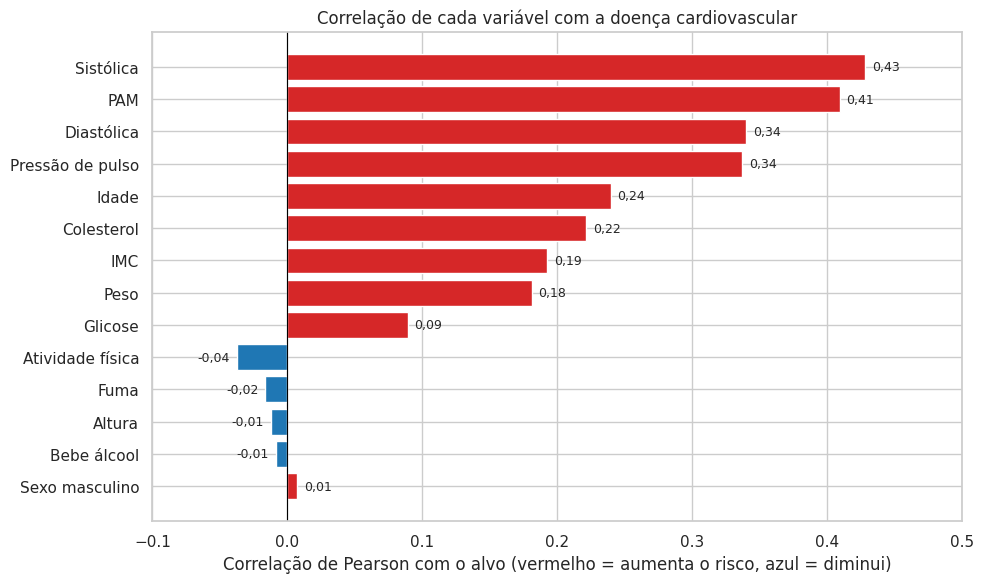

,pearson,spearman,conjunto
Sistólica,0.428,0.452,A
PAM,0.409,0.433,B (derivada)
Diastólica,0.340,0.357,A
Pressão de pulso,0.337,0.358,B (derivada)
Idade,0.240,0.236,A
Colesterol,0.221,0.215,A
IMC,0.193,0.198,B (derivada)
Peso,0.181,0.181,A
Glicose,0.089,0.092,A
Atividade física,-0.038,-0.038,A


In [5]:
features = FEATURES_B_NUMERICAS
ranking = pd.DataFrame({
    "pearson": df[features].corrwith(df[TARGET]),
    "spearman": df[features].corrwith(df[TARGET], method="spearman"),
})
ranking["conjunto"] = ["B (derivada)" if c in DERIVADAS_NUMERICAS else "A" for c in ranking.index]
ranking = ranking.reindex(ranking["pearson"].abs().sort_values(ascending=False).index)

fig, ax = plt.subplots(figsize=(10, 6))
cores = ["tab:red" if r > 0 else "tab:blue" for r in ranking["pearson"]]
ax.barh([NOMES[c] for c in ranking.index], ranking["pearson"], color=cores)
ax.invert_yaxis()
ax.axvline(0, color="black", linewidth=0.8)
for i, valor in enumerate(ranking["pearson"]):
    ax.text(valor + (0.005 if valor >= 0 else -0.005), i, num(valor), va="center",
            ha="left" if valor >= 0 else "right", fontsize=9)
ax.set(title="Correlação de cada variável com a doença cardiovascular",
       xlabel="Correlação de Pearson com o alvo (vermelho = aumenta o risco, azul = diminui)", ylabel="",
       xlim=(-0.1, 0.5))
plt.tight_layout()
salvar(fig, "ranking_alvo")
plt.show()

ranking.rename(index=NOMES).round(3)

In [6]:
ESPERADO = {"ap_hi": 0.43, "ap_lo": 0.34, "age_years": 0.24, "cholesterol": 0.22, "weight": 0.18}
comparacao = pd.DataFrame({"esperado (issue)": ESPERADO, "calculado": ranking.loc[list(ESPERADO), "pearson"]})
comparacao["diferença"] = comparacao["calculado"] - comparacao["esperado (issue)"]
display(comparacao.rename(index=NOMES).round(3))

originais = ranking[ranking["conjunto"] == "A"]
top5 = [NOMES[c] for c in originais.index[:5]]
negativas = originais[originais["pearson"] < 0]
fracas = originais[originais["pearson"].abs() < 0.05]
bate = (comparacao["diferença"].abs() < 0.02).all()

texto(f"""**Interpretação:**

- Entre as variáveis originais, as 5 mais correlacionadas com a doença são: **{", ".join(top5)}**.
  {"Os valores batem com os esperados na issue (diferença menor que 0,02 em todas)." if bate else
   "Alguns valores diferem dos esperados na issue em mais de 0,02 (ver tabela acima)."}
- A **pressão arterial** domina: a sistólica ({num(ranking.loc["ap_hi", "pearson"])}) e a PAM
  ({num(ranking.loc["pam", "pearson"])}) lideram. A **PAM** e a **pressão de pulso** (conjunto B) não superam a
  sistólica sozinha, o que é esperado: são combinações da sistólica e da diastólica (seção 3).
- O **IMC** ({num(ranking.loc["imc", "pearson"])}) é um pouco mais correlacionado que o peso
  ({num(ranking.loc["weight", "pearson"])}), porque corrige o peso pela altura; a altura sozinha quase não tem relação
  com a doença ({num(ranking.loc["height", "pearson"], 3)}).
- {len(fracas)} variáveis originais têm correlação abaixo de 0,05 em módulo: {", ".join(NOMES[c] for c in fracas.index)}.
  {len(negativas)} têm sinal negativo ({", ".join(NOMES[c] for c in negativas.index)}): para fumo e álcool o sinal é
  contrário ao esperado clinicamente, o que a T06 já investigou (autodeclaração e causalidade reversa).
- Pearson e Spearman ficam próximos em todas as variáveis (maior diferença:
  {num((ranking["spearman"] - ranking["pearson"]).abs().max(), 3)}), então as relações são aproximadamente
  monotônicas. Isso **não** quer dizer que sejam lineares: a seção 5 mostra um efeito de limiar na pressão.
- Nenhuma correlação passa de {num(ranking["pearson"].abs().max())}: cada variável sozinha explica pouco, e o modelo
  precisa combinar várias delas.""")

,esperado (issue),calculado,diferença
Sistólica,0.43,0.428,-0.002
Diastólica,0.34,0.340,0.000
Idade,0.24,0.240,-0.000
Colesterol,0.22,0.221,0.001
Peso,0.18,0.181,0.001


**Interpretação:**

- Entre as variáveis originais, as 5 mais correlacionadas com a doença são: **Sistólica, Diastólica, Idade, Colesterol, Peso**.
  Os valores batem com os esperados na issue (diferença menor que 0,02 em todas).
- A **pressão arterial** domina: a sistólica (0,43) e a PAM
  (0,41) lideram. A **PAM** e a **pressão de pulso** (conjunto B) não superam a
  sistólica sozinha, o que é esperado: são combinações da sistólica e da diastólica (seção 3).
- O **IMC** (0,19) é um pouco mais correlacionado que o peso
  (0,18), porque corrige o peso pela altura; a altura sozinha quase não tem relação
  com a doença (-0,012).
- 5 variáveis originais têm correlação abaixo de 0,05 em módulo: Atividade física, Fuma, Altura, Bebe álcool, Sexo masculino.
  4 têm sinal negativo (Atividade física, Fuma, Altura, Bebe álcool): para fumo e álcool o sinal é
  contrário ao esperado clinicamente, o que a T06 já investigou (autodeclaração e causalidade reversa).
- Pearson e Spearman ficam próximos em todas as variáveis (maior diferença:
  0,024), então as relações são aproximadamente
  monotônicas. Isso **não** quer dizer que sejam lineares: a seção 5 mostra um efeito de limiar na pressão.
- Nenhuma correlação passa de 0,43: cada variável sozinha explica pouco, e o modelo
  precisa combinar várias delas.

## 3. Pares muito correlacionados (multicolinearidade)

Variáveis muito correlacionadas entre si carregam a mesma informação. Isso não costuma piorar a **previsão**, mas atrapalha
a **interpretação** de alguns modelos. Além da correlação entre pares, o **VIF** (fator de inflação da variância) mede
quanto cada variável é explicada por **todas** as outras juntas: VIF = 1 / (1 − R²), onde R² vem de uma regressão linear
da variável contra as demais. A regra usual é: VIF acima de 5 a 10 indica multicolinearidade forte; infinito indica que a
variável é uma combinação exata das outras.

In [7]:
def vif(dados: pd.DataFrame) -> pd.Series:
    """VIF de cada coluna: 1 / (1 - R²) da regressão linear dela contra as demais."""
    valores = {}
    for coluna in dados.columns:
        outras = dados.drop(columns=coluna)
        r2 = LinearRegression().fit(outras, dados[coluna]).score(outras, dados[coluna])
        valores[coluna] = np.inf if r2 > 1 - 1e-9 else 1 / (1 - r2)
    return pd.Series(valores)


correlacao_features = df[FEATURES_B_NUMERICAS].corr()
pares = (correlacao_features.where(np.triu(np.ones_like(correlacao_features, dtype=bool), k=1)).stack()
         .rename("correlação").reset_index())
pares = pares[pares["correlação"].abs() >= 0.5].sort_values("correlação", key=abs, ascending=False)
pares["par"] = pares["level_0"].map(NOMES) + " × " + pares["level_1"].map(NOMES)
display(pares[["par", "correlação"]].set_index("par").round(3))

vifs = pd.DataFrame({
    "VIF conjunto A": vif(df[FEATURES_A].astype(float)),
    "VIF conjunto B": vif(df[FEATURES_B_NUMERICAS].astype(float)),
}).reindex(FEATURES_B_NUMERICAS)
vifs.rename(index=NOMES).round(1)

,correlação
par,
Diastólica × PAM,0.940
Sistólica × PAM,0.922
Peso × IMC,0.865
Sistólica × Pressão de pulso,0.835
Sistólica × Diastólica,0.735
Pressão de pulso × PAM,0.558
Sexo masculino × Altura,0.522


,VIF conjunto A,VIF conjunto B
Idade,1.1,1.1
Sexo masculino,1.5,1.5
Altura,1.5,28.9
Peso,1.2,110.1
Sistólica,2.3,inf
Diastólica,2.2,inf
Colesterol,1.3,1.3
Glicose,1.3,1.3
Fuma,1.2,1.2
Bebe álcool,1.1,1.1


In [8]:
r_pressoes = correlacao_features.loc["ap_hi", "ap_lo"]
r_peso_imc = correlacao_features.loc["weight", "imc"]
vif_a = vifs["VIF conjunto A"]
infinitos = [NOMES[c] for c in vifs.index if np.isinf(vifs.loc[c, "VIF conjunto B"])]
altos_b = [f"{NOMES[c]} {num(vifs.loc[c, 'VIF conjunto B'], 0)}" for c in vifs.index
           if 10 < vifs.loc[c, "VIF conjunto B"] < np.inf]

texto(f"""**Interpretação:**

- **Sistólica × diastólica:** correlação de {num(r_pressoes)}. São medidas diferentes (pico e repouso da pressão),
  mas sobem juntas. **Peso × IMC:** {num(r_peso_imc)}, já que o IMC é calculado a partir do peso.
- **Conjunto A:** o maior VIF é {num(vif_a.max(), 1)} ({NOMES[vif_a.idxmax()]}), bem abaixo de 5. As variáveis originais
  são correlacionadas, mas **não redundantes**: a Regressão Logística consegue estimar um coeficiente estável para cada uma.
- **Conjunto B:** {", ".join(infinitos)} têm **VIF infinito**. A PAM, (sistólica + 2 × diastólica) / 3, e a pressão de pulso,
  sistólica − diastólica, são **combinações lineares exatas** das duas pressões, então as quatro colunas carregam só duas
  informações. {"Altura, peso e IMC também ficam com VIF alto (" + ", ".join(altos_b) + "): o IMC é calculado a partir dos outros dois, só que de forma não linear (peso / altura²), por isso o VIF é alto mas não infinito." if altos_b else ""}

**Isso atrapalha algum modelo?**

- **Regressão Logística e SVM linear (T15 e T19):** a previsão não piora, mas os **coeficientes do conjunto B deixam de
  ser interpretáveis**. O efeito da pressão é dividido de forma arbitrária entre sistólica, diastólica, PAM e pressão de
  pulso, e os coeficientes podem até trocar de sinal. Sem regularização o ajuste nem teria solução única; com a
  regularização L2 do scikit-learn (padrão) ele converge, mas a divisão continua arbitrária. **Os odds ratio (T15) devem
  ser lidos no conjunto A.**
- **KNN (T16):** variáveis redundantes contam mais de uma vez na distância. No conjunto B a pressão aparece em 4 colunas
  escalonadas, então pesa mais que idade ou colesterol na escolha dos vizinhos.
- **Random Forest e XGBoost (T17 e T18):** a previsão não é afetada, mas a **importância** se divide entre as variáveis
  correlacionadas. Na feature importance e no SHAP (T24 e T25), é melhor somar a importância das colunas de pressão
  (e das de peso/IMC) antes de concluir qual variável importa mais.""")

**Interpretação:**

- **Sistólica × diastólica:** correlação de 0,73. São medidas diferentes (pico e repouso da pressão),
  mas sobem juntas. **Peso × IMC:** 0,86, já que o IMC é calculado a partir do peso.
- **Conjunto A:** o maior VIF é 2,3 (Sistólica), bem abaixo de 5. As variáveis originais
  são correlacionadas, mas **não redundantes**: a Regressão Logística consegue estimar um coeficiente estável para cada uma.
- **Conjunto B:** Sistólica, Diastólica, Pressão de pulso, PAM têm **VIF infinito**. A PAM, (sistólica + 2 × diastólica) / 3, e a pressão de pulso,
  sistólica − diastólica, são **combinações lineares exatas** das duas pressões, então as quatro colunas carregam só duas
  informações. Altura, peso e IMC também ficam com VIF alto (Altura 29, Peso 110, IMC 103): o IMC é calculado a partir dos outros dois, só que de forma não linear (peso / altura²), por isso o VIF é alto mas não infinito.

**Isso atrapalha algum modelo?**

- **Regressão Logística e SVM linear (T15 e T19):** a previsão não piora, mas os **coeficientes do conjunto B deixam de
  ser interpretáveis**. O efeito da pressão é dividido de forma arbitrária entre sistólica, diastólica, PAM e pressão de
  pulso, e os coeficientes podem até trocar de sinal. Sem regularização o ajuste nem teria solução única; com a
  regularização L2 do scikit-learn (padrão) ele converge, mas a divisão continua arbitrária. **Os odds ratio (T15) devem
  ser lidos no conjunto A.**
- **KNN (T16):** variáveis redundantes contam mais de uma vez na distância. No conjunto B a pressão aparece em 4 colunas
  escalonadas, então pesa mais que idade ou colesterol na escolha dos vizinhos.
- **Random Forest e XGBoost (T17 e T18):** a previsão não é afetada, mas a **importância** se divide entre as variáveis
  correlacionadas. Na feature importance e no SHAP (T24 e T25), é melhor somar a importância das colunas de pressão
  (e das de peso/IMC) antes de concluir qual variável importa mais.

## 4. Checagem de vazamento

Há vazamento quando uma coluna entrega a resposta ao modelo de um jeito que não estaria disponível no uso real. Dois
riscos neste dataset:

1. **O `id`:** se os pacientes tivessem sido numerados em ordem (ex.: primeiro os doentes), o modelo poderia aprender o
   diagnóstico pelo número. O `id` precisa ter correlação ≈ 0 com o alvo.
2. **Variáveis que são consequência do diagnóstico:** por exemplo, um remédio ou um exame pedido só depois de confirmar a
   doença. Nesse caso a variável seria efeito, e não causa, da doença.

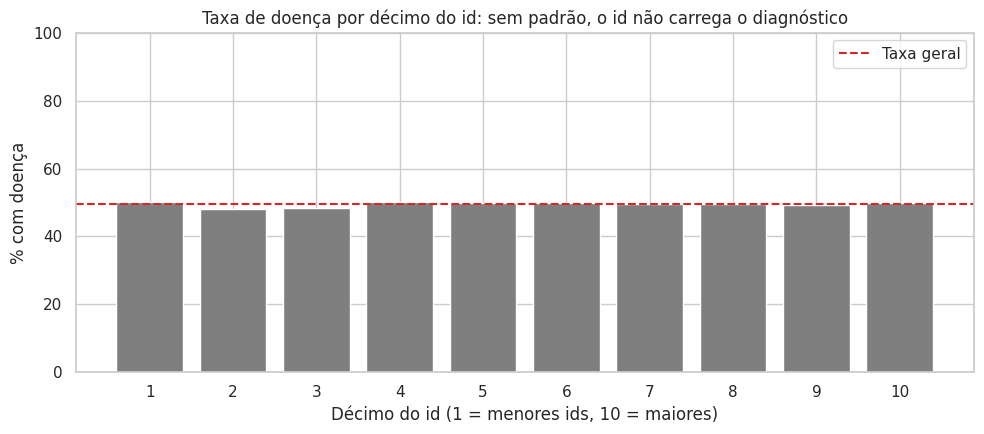

Correlação id × alvo: 0.0037 (p-valor = 0.34) | AUC usando só o id: 0.5021


In [9]:
r_id, p_id = stats.pearsonr(df["id"], df[TARGET])
auc_id = roc_auc_score(df[TARGET], df["id"])

faixas_id = pd.qcut(df["id"], 10)
taxa_id = df.groupby(faixas_id, observed=True)[TARGET].mean()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(range(1, 11), taxa_id * 100, color="tab:gray")
ax.axhline(df[TARGET].mean() * 100, color="tab:red", linestyle="--", label="Taxa geral")
ax.set(title="Taxa de doença por décimo do id: sem padrão, o id não carrega o diagnóstico",
       xlabel="Décimo do id (1 = menores ids, 10 = maiores)", ylabel="% com doença", ylim=(0, 100), xticks=range(1, 11))
ax.legend()
plt.tight_layout()
salvar(fig, "vazamento_id")
plt.show()

print(f"Correlação id × alvo: {r_id:.4f} (p-valor = {p_id:.2f}) | AUC usando só o id: {auc_id:.4f}")

In [10]:
ORIGEM = pd.DataFrame([
    ("age_years", "Cadastro (data de nascimento)", "Não"),
    ("sex_male", "Cadastro", "Não"),
    ("height", "Medida no exame", "Não"),
    ("weight", "Medida no exame", "Não"),
    ("ap_hi", "Medida no exame", "Não; pode estar baixa em quem já trata a hipertensão"),
    ("ap_lo", "Medida no exame", "Não; pode estar baixa em quem já trata a hipertensão"),
    ("cholesterol", "Exame de sangue", "Não; pode estar baixo em quem já usa remédio"),
    ("gluc", "Exame de sangue", "Não"),
    ("smoke", "Autodeclarado", "Não; mas pode mudar depois do diagnóstico (quem para de fumar)"),
    ("alco", "Autodeclarado", "Não; mas pode mudar depois do diagnóstico"),
    ("active", "Autodeclarado", "Não; mas pode mudar depois do diagnóstico"),
], columns=["variavel", "origem", "consequência direta do diagnóstico?"])
ORIGEM["correlação com o alvo"] = ORIGEM["variavel"].map(ranking["pearson"]).round(3)
ORIGEM["variavel"] = ORIGEM["variavel"].map(NOMES)
ORIGEM.set_index("variavel")

,origem,consequência direta do diagnóstico?,correlação com o alvo
variavel,,,
Idade,Cadastro (data de nascimento),Não,0.240
Sexo masculino,Cadastro,Não,0.007
Altura,Medida no exame,Não,-0.012
Peso,Medida no exame,Não,0.181
Sistólica,Medida no exame,Não; pode estar baixa em quem já trata a hiper...,0.428
Diastólica,Medida no exame,Não; pode estar baixa em quem já trata a hiper...,0.340
Colesterol,Exame de sangue,Não; pode estar baixo em quem já usa remédio,0.221
Glicose,Exame de sangue,Não,0.089
Fuma,Autodeclarado,Não; mas pode mudar depois do diagnóstico (que...,-0.016


In [11]:
texto(f"""**Conclusão sobre vazamento:**

- **O `id` não tem relação com o alvo:** correlação de {num(r_id, 4)} (p-valor = {num(p_id)}, ou seja, indistinguível de
  zero) e AUC de {num(auc_id, 3)} usando só o `id`, o mesmo que sortear. A taxa de doença fica próxima da taxa geral em
  todos os décimos do `id` (de {pct(taxa_id.min(), 1)} a {pct(taxa_id.max(), 1)}). Mesmo assim, o `id` **nunca entra
  nas features**: ele é só um identificador, e `load_splits()` o usa como índice. A T12 tem um teste que garante isso.
- **Nenhuma variável é consequência direta do diagnóstico:** todas são cadastro, medidas do exame ou hábitos declarados,
  disponíveis no momento da triagem. A correlação mais alta com o alvo é {num(ranking["pearson"].abs().max())}
  (sistólica), muito longe de 1; uma coluna que entregasse a resposta teria correlação perto de 1 e daria ao modelo uma
  acurácia irrealmente alta.
- **Ressalvas que não são vazamento, mas limitam a interpretação:** o dataset não informa se o paciente já trata a doença.
  Pressão e colesterol de quem já usa remédio podem estar mais baixos, e os hábitos autodeclarados podem mudar depois do
  diagnóstico (causalidade reversa, discutida na T06). Isso enfraquece a relação dessas variáveis com o alvo, mas não
  entrega a resposta. Fica registrado como limitação para o relatório (T34).
- **As derivadas do conjunto B (T10) também são seguras:** são funções diretas de peso, altura e pressões, calculadas
  paciente a paciente, sem usar o alvo nem estatísticas do dataset.""")

**Conclusão sobre vazamento:**

- **O `id` não tem relação com o alvo:** correlação de 0,0037 (p-valor = 0,34, ou seja, indistinguível de
  zero) e AUC de 0,502 usando só o `id`, o mesmo que sortear. A taxa de doença fica próxima da taxa geral em
  todos os décimos do `id` (de 48,1% a 50,2%). Mesmo assim, o `id` **nunca entra
  nas features**: ele é só um identificador, e `load_splits()` o usa como índice. A T12 tem um teste que garante isso.
- **Nenhuma variável é consequência direta do diagnóstico:** todas são cadastro, medidas do exame ou hábitos declarados,
  disponíveis no momento da triagem. A correlação mais alta com o alvo é 0,43
  (sistólica), muito longe de 1; uma coluna que entregasse a resposta teria correlação perto de 1 e daria ao modelo uma
  acurácia irrealmente alta.
- **Ressalvas que não são vazamento, mas limitam a interpretação:** o dataset não informa se o paciente já trata a doença.
  Pressão e colesterol de quem já usa remédio podem estar mais baixos, e os hábitos autodeclarados podem mudar depois do
  diagnóstico (causalidade reversa, discutida na T06). Isso enfraquece a relação dessas variáveis com o alvo, mas não
  entrega a resposta. Fica registrado como limitação para o relatório (T34).
- **As derivadas do conjunto B (T10) também são seguras:** são funções diretas de peso, altura e pressões, calculadas
  paciente a paciente, sem usar o alvo nem estatísticas do dataset.

## 5. Relações não lineares

A correlação de Pearson resume a relação numa reta. Para ver a forma real, a taxa de doença é calculada por **faixas** de
idade, de pressão sistólica e de pressão diastólica.

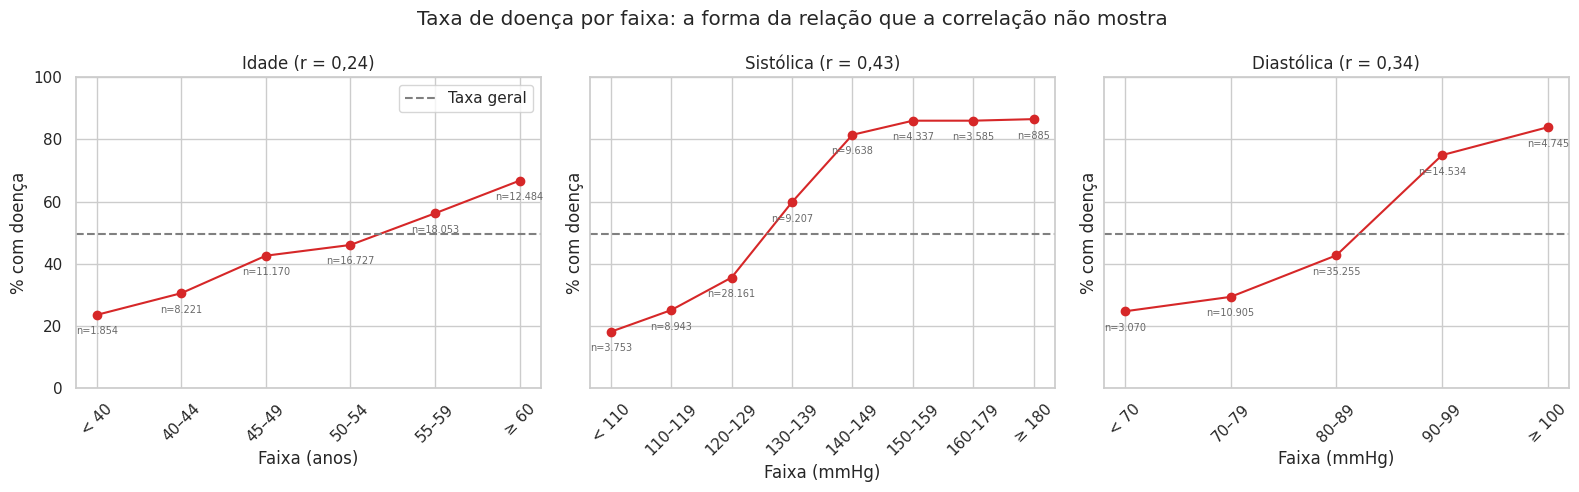

In [12]:
FAIXAS = {
    "age_years": ([0, 40, 45, 50, 55, 60, 70], "anos"),
    "ap_hi": ([0, 110, 120, 130, 140, 150, 160, 180, 251], "mmHg"),
    "ap_lo": ([0, 70, 80, 90, 100, 201], "mmHg"),
}


def rotulo(intervalo: pd.Interval, primeiro: bool, ultimo: bool) -> str:
    esquerda, direita = int(intervalo.left), int(intervalo.right)
    if primeiro:
        return f"< {direita}"
    if ultimo:
        return f"≥ {esquerda}"
    return f"{esquerda}–{direita - 1}"


taxas_faixa = {}
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, (coluna, (limites, unidade)) in zip(axes, FAIXAS.items()):
    tabela = df.groupby(pd.cut(df[coluna], limites, right=False), observed=True)[TARGET].agg(taxa="mean", n="size")
    tabela.index = [rotulo(i, k == 0, k == len(tabela) - 1) for k, i in enumerate(tabela.index)]
    taxas_faixa[coluna] = tabela
    ax.plot(tabela.index, tabela["taxa"] * 100, marker="o", color="tab:red")
    ax.axhline(df[TARGET].mean() * 100, color="gray", linestyle="--", label="Taxa geral")
    ax.set(title=f"{NOMES[coluna]} (r = {num(ranking.loc[coluna, 'pearson'])})",
           xlabel=f"Faixa ({unidade})", ylabel="% com doença", ylim=(0, 100))
    ax.tick_params(axis="x", rotation=45)
    for x, (taxa, n) in enumerate(zip(tabela["taxa"], tabela["n"])):
        ax.annotate(f"n={inteiro(n)}", (x, taxa * 100), textcoords="offset points", xytext=(0, -14),
                    ha="center", fontsize=7, color="dimgray")
axes[0].legend()
fig.suptitle("Taxa de doença por faixa: a forma da relação que a correlação não mostra")
plt.tight_layout()
salvar(fig, "taxa_por_faixa")
plt.show()

In [13]:
idade, sist, diast = taxas_faixa["age_years"], taxas_faixa["ap_hi"], taxas_faixa["ap_lo"]
saltos = sist["taxa"].diff()
maior_salto = saltos.idxmax()
anterior = sist.index[sist.index.get_loc(maior_salto) - 1]
acima_140 = sist.loc[["140–149", "150–159", "160–179", "≥ 180"], "taxa"]
abaixo_120 = sist.loc[["< 110", "110–119"], "taxa"]
saltos_diast = diast["taxa"].diff()
maior_salto_diast = saltos_diast.idxmax()

texto(f"""**Interpretação:**

- **Idade:** a taxa sobe de forma contínua, de {pct(idade["taxa"].iloc[0])} abaixo de 40 anos para
  {pct(idade["taxa"].iloc[-1])} a partir de 60, sem saltos. É a relação mais próxima de uma reta, e a correlação
  ({num(ranking.loc["age_years", "pearson"])}) a descreve bem.
- **Sistólica:** a relação tem **efeito de limiar**. A taxa fica baixa abaixo de 120 mmHg ({pct(abaixo_120.min())} a
  {pct(abaixo_120.max())}), dá o maior salto entre as faixas **{anterior}** e **{maior_salto}** mmHg
  (+{num(saltos.max() * 100, 0)} pontos) e se **estabiliza** acima de 140 mmHg, entre {pct(acima_140.min())} e
  {pct(acima_140.max())}. Uma reta subestima o salto em torno de 130–140 e superestima o efeito de subir de 150 para 180.
- **Diastólica:** mesmo padrão, com o maior salto entre {diast.index[diast.index.get_loc(maior_salto_diast) - 1]} e
  {maior_salto_diast} mmHg (+{num(saltos_diast.max() * 100, 0)} pontos).
- **Consequências:** os limiares coincidem com as faixas clínicas da diretriz ACC/AHA (120, 130 e 140 mmHg), o que
  **justifica a `categoria_pressao` da T10**. Modelos de árvore (Random Forest e XGBoost) capturam esses degraus
  sozinhos; para os modelos lineares (Regressão Logística e SVM linear), a variável categórica ajuda a representar o
  limiar que a pressão contínua não representa.""")

**Interpretação:**

- **Idade:** a taxa sobe de forma contínua, de 24% abaixo de 40 anos para
  67% a partir de 60, sem saltos. É a relação mais próxima de uma reta, e a correlação
  (0,24) a descreve bem.
- **Sistólica:** a relação tem **efeito de limiar**. A taxa fica baixa abaixo de 120 mmHg (18% a
  25%), dá o maior salto entre as faixas **120–129** e **130–139** mmHg
  (+24 pontos) e se **estabiliza** acima de 140 mmHg, entre 82% e
  87%. Uma reta subestima o salto em torno de 130–140 e superestima o efeito de subir de 150 para 180.
- **Diastólica:** mesmo padrão, com o maior salto entre 80–89 e
  90–99 mmHg (+32 pontos).
- **Consequências:** os limiares coincidem com as faixas clínicas da diretriz ACC/AHA (120, 130 e 140 mmHg), o que
  **justifica a `categoria_pressao` da T10**. Modelos de árvore (Random Forest e XGBoost) capturam esses degraus
  sozinhos; para os modelos lineares (Regressão Logística e SVM linear), a variável categórica ajuda a representar o
  limiar que a pressão contínua não representa.

## 6. Conclusões

In [14]:
texto(f"""- **Ranking com o alvo:** a pressão arterial domina (sistólica {num(ranking.loc["ap_hi", "pearson"])}, diastólica
  {num(ranking.loc["ap_lo", "pearson"])}), seguida de idade ({num(ranking.loc["age_years", "pearson"])}), colesterol
  ({num(ranking.loc["cholesterol", "pearson"])}) e peso ({num(ranking.loc["weight", "pearson"])}). Hábitos, sexo e altura
  têm correlação perto de zero.
- **A limpeza é necessária:** sem ela, a correlação da sistólica com o alvo cai de {num(r_limpo["ap_hi"])} para
  {num(r_bruto["ap_hi"])}.
- **Multicolinearidade:** o conjunto A não tem problema (VIF máximo {num(vif_a.max(), 1)}). No conjunto B, PAM e pressão
  de pulso são combinações exatas das pressões (VIF infinito): a previsão não piora, mas os coeficientes da Regressão
  Logística e do SVM linear devem ser interpretados no conjunto A, e a importância das árvores deve ser somada por grupo.
- **Vazamento:** não há. O `id` não tem relação com o alvo (r = {num(r_id, 4)}, AUC = {num(auc_id, 3)}) e fica fora das
  features; nenhuma variável é consequência direta do diagnóstico. A falta de informação sobre tratamento é limitação,
  não vazamento.
- **Não linearidade:** a idade é quase linear, mas a pressão tem degraus nos limiares clínicos (120, 130 e 140 mmHg) e
  estabiliza acima de 140. Isso sustenta a `categoria_pressao` (T10) e favorece modelos de árvore.

**Alimenta:** T10 (variáveis derivadas e categoria de pressão), T12 (teste de que `id` e `cardio` não entram nas
features), T15 (ler os odds ratio no conjunto A), T24/T25 (somar a importância de variáveis correlacionadas) e T34
(limitações).""")

- **Ranking com o alvo:** a pressão arterial domina (sistólica 0,43, diastólica
  0,34), seguida de idade (0,24), colesterol
  (0,22) e peso (0,18). Hábitos, sexo e altura
  têm correlação perto de zero.
- **A limpeza é necessária:** sem ela, a correlação da sistólica com o alvo cai de 0,43 para
  0,05.
- **Multicolinearidade:** o conjunto A não tem problema (VIF máximo 2,3). No conjunto B, PAM e pressão
  de pulso são combinações exatas das pressões (VIF infinito): a previsão não piora, mas os coeficientes da Regressão
  Logística e do SVM linear devem ser interpretados no conjunto A, e a importância das árvores deve ser somada por grupo.
- **Vazamento:** não há. O `id` não tem relação com o alvo (r = 0,0037, AUC = 0,502) e fica fora das
  features; nenhuma variável é consequência direta do diagnóstico. A falta de informação sobre tratamento é limitação,
  não vazamento.
- **Não linearidade:** a idade é quase linear, mas a pressão tem degraus nos limiares clínicos (120, 130 e 140 mmHg) e
  estabiliza acima de 140. Isso sustenta a `categoria_pressao` (T10) e favorece modelos de árvore.

**Alimenta:** T10 (variáveis derivadas e categoria de pressão), T12 (teste de que `id` e `cardio` não entram nas
features), T15 (ler os odds ratio no conjunto A), T24/T25 (somar a importância de variáveis correlacionadas) e T34
(limitações).